# Predicting Kenyan Market Food Prices for Smallholder Farmers

**Mission:** help smallholder farmers get fair prices for their produce.

**Use case:** a smallholder farmer (or the cooperative / extension officer advising them) wants to know the price per kg they
can expect for a crop at a given market, month and selling channel (retail vs wholesale). With that estimate they can decide
**where** and **when** to sell, and spot when a trader's offer is far below the going rate.

**Dataset:** [WFP Kenya Food Prices (HDX)](https://data.humdata.org/dataset/wfp-food-prices-for-kenya) — World Food Programme
market price monitoring, 2006–2026, ~29,000 rows, 16 columns (numeric: latitude, longitude, price, usdprice, ids;
categorical: region, county, market, category, commodity, unit, price type, price flag, currency).

**Target:** price in KES per kg (or per litre), a continuous number.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load and inspect the data

In [2]:
raw = pd.read_csv("wfp_food_prices_ken.csv")
print(raw.shape)
raw.head()

(29298, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,16.13,0.22
1,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize (white),67,90 KG,actual,Wholesale,KES,1480.00,20.58
2,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans,50,KG,actual,Wholesale,KES,33.63,0.47
3,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans (dry),262,90 KG,actual,Wholesale,KES,3246.00,45.15
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.00,0.24


In [3]:
raw.info()
print("\nMissing values:\n", raw.isna().sum()[raw.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 29298 entries, 0 to 29297
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          29298 non-null  str    
 1   admin1        29230 non-null  str    
 2   admin2        29230 non-null  str    
 3   market        29298 non-null  str    
 4   market_id     29298 non-null  int64  
 5   latitude      29230 non-null  float64
 6   longitude     29230 non-null  float64
 7   category      29298 non-null  str    
 8   commodity     29298 non-null  str    
 9   commodity_id  29298 non-null  int64  
 10  unit          29298 non-null  str    
 11  priceflag     29298 non-null  str    
 12  pricetype     29298 non-null  str    
 13  currency      29298 non-null  str    
 14  price         29298 non-null  float64
 15  usdprice      29298 non-null  float64
dtypes: float64(4), int64(2), str(10)
memory usage: 3.6 MB

Missing values:
 admin1       68
admin2       68
latitude     68
lon

In [4]:
print(raw["unit"].value_counts())

unit
KG        15609
90 KG      4208
L          2862
50 KG      2022
200 G      1460
500 ML      842
Unit        608
64 KG       522
13 KG       478
126 KG      461
400 G       178
Head         26
Bunch        22
Name: count, dtype: int64


## 2. Cleaning and feature engineering

Prices are quoted in very different units (1 KG, 90 KG bag, 200 G packet, 500 ML bottle…), so the raw `price` column is not
comparable across rows. I convert every price to **KES per kg (or per litre)** using the pack size, and keep the pack size as a
feature because bulk bags (wholesale) are cheaper per kg than small packets.

**Rows removed**
- Units with no weight (`Unit`, `Head`, `Bunch` — bananas, cabbage, kale): price per kg cannot be computed.
- `non-food` category (fuel, etc.): not relevant to farmers selling produce.
- 68 rows from one market with missing region and coordinates.

**Columns dropped and why**
| Column | Reason |
|---|---|
| `currency` | Constant (always KES) — carries no information |
| `usdprice` | Same as the target converted to USD — would leak the answer |
| `price`, `unit` | Replaced by the target `price_per_kg` and the numeric `pack_size` |
| `commodity_id`, `market_id` | Numeric ids duplicating `commodity` / `market` |
| `market`, `admin2` | 227 / 27 levels; location is already captured by `latitude`, `longitude` and `admin1` |
| `category` | Fully determined by `commodity`, so redundant |
| `priceflag` | Data-collection metadata (actual vs aggregate), not something a farmer knows or controls |
| `date` | Split into `year` (captures inflation) and `month` (captures harvest seasonality) |

In [5]:
UNIT_TO_KG = {"KG": 1, "90 KG": 90, "50 KG": 50, "64 KG": 64, "13 KG": 13, "126 KG": 126,
              "200 G": 0.2, "400 G": 0.4, "L": 1, "500 ML": 0.5}

CATEGORICAL = ["commodity", "pricetype", "admin1"]
NUMERIC = ["latitude", "longitude", "year", "month", "pack_size"]
FEATURES = CATEGORICAL + NUMERIC
TARGET = "price_per_kg"


def clean(df: pd.DataFrame) -> pd.DataFrame:
    """Turn raw WFP rows into model-ready rows (same function is used by the API's /retrain)."""
    df = df[df["unit"].isin(UNIT_TO_KG.keys()) & (df["category"] != "non-food")].copy()
    dates = pd.to_datetime(df["date"])
    df["year"] = dates.dt.year
    df["month"] = dates.dt.month
    df["pack_size"] = df["unit"].map(UNIT_TO_KG)
    df[TARGET] = df["price"] / df["pack_size"]
    df = df.dropna(subset=FEATURES + [TARGET])
    df = df[df[TARGET] > 0]
    return df[FEATURES + [TARGET]].reset_index(drop=True)


data = clean(raw)
print(data.shape)
data.head()

(28373, 9)


,commodity,pricetype,admin1,latitude,longitude,year,month,pack_size,price_per_kg
0,Maize,Wholesale,Coast,-4.05,39.67,2006,1,1.0,16.130000
1,Maize (white),Wholesale,Coast,-4.05,39.67,2006,1,90.0,16.444444
2,Beans,Wholesale,Coast,-4.05,39.67,2006,1,1.0,33.630000
3,Beans (dry),Wholesale,Coast,-4.05,39.67,2006,1,90.0,36.066667
4,Maize (white),Retail,Eastern,-1.37,38.02,2006,1,1.0,17.000000


In [6]:
data.describe()

,latitude,longitude,year,month,pack_size,price_per_kg
count,28373.000000,28373.000000,28373.000000,28373.000000,28373.000000,28373.000000
mean,0.811806,37.024041,2021.024953,6.569062,21.024009,118.617645
std,2.278145,2.066990,4.829740,3.446423,35.697571,116.380248
min,-4.660000,34.360000,2006.000000,1.000000,0.200000,0.277778
25%,-1.260000,34.850000,2021.000000,3.000000,1.000000,50.000000
50%,0.470000,36.780000,2023.000000,6.000000,1.000000,88.360000
75%,3.540000,39.170000,2024.000000,9.000000,50.000000,140.000000
max,4.620000,41.860000,2026.000000,12.000000,126.000000,900.000000


## 3. Exploratory plots

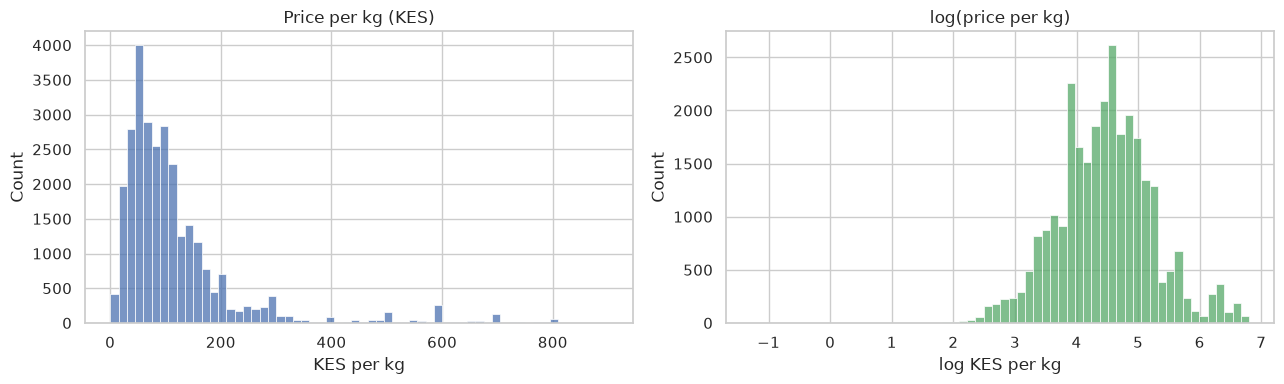

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data[TARGET], bins=60, ax=axes[0], color="#4C72B0")
axes[0].set(title="Price per kg (KES)", xlabel="KES per kg")
sns.histplot(np.log(data[TARGET]), bins=60, ax=axes[1], color="#55A868")
axes[1].set(title="log(price per kg)", xlabel="log KES per kg")
plt.tight_layout(); plt.show()

**What it shows:** price per kg is strongly right-skewed — most items cost under 150 KES/kg but meat, oil and milk reach
900 KES/kg. After a log transform the distribution is close to symmetric.

**Decision:** I train every model on **log(price per kg)**. This stops a few expensive items from dominating the squared error,
makes the relationship with the features closer to linear (a commodity or region shifts prices by a *percentage*), and the
API converts predictions back to KES with `exp`.

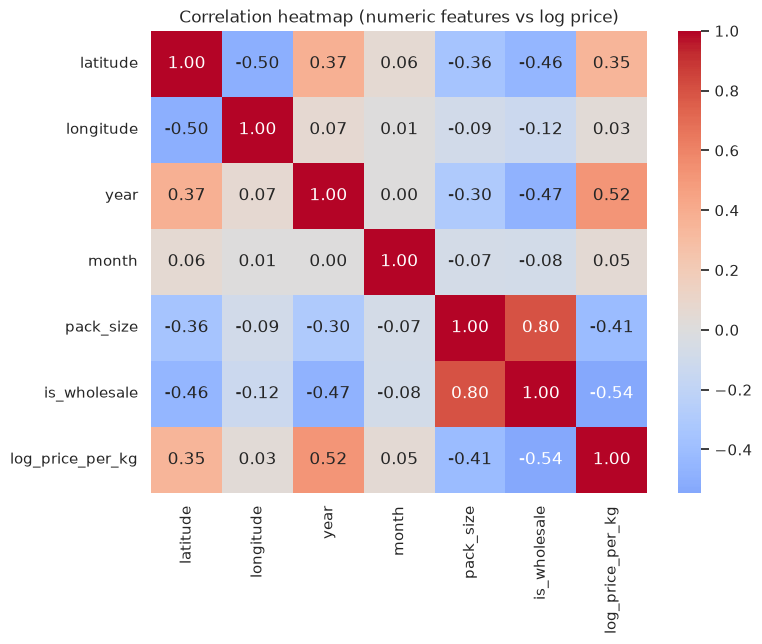

is_wholesale   -0.544850
year            0.520494
pack_size      -0.414888
latitude        0.345492
month           0.047327
longitude       0.034868
Name: log_price_per_kg, dtype: float64

In [8]:
corr_df = data[NUMERIC].copy()
corr_df["is_wholesale"] = (data["pricetype"] == "Wholesale").astype(int)
corr_df["log_price_per_kg"] = np.log(data[TARGET])
plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap (numeric features vs log price)")
plt.show()
corr_df.corr()["log_price_per_kg"].drop("log_price_per_kg").sort_values(key=abs, ascending=False)

**What it shows:** the strongest correlations with log price are `is_wholesale` (−0.54, wholesale is cheaper per kg),
`year` (+0.52, inflation) and `pack_size` (−0.41, bulk bags are cheaper per kg). `latitude` (+0.35) shows that northern markets
are pricier. `month` and `longitude` are only weakly *linearly* related, and `pack_size` overlaps strongly with `is_wholesale`.

**Decision:** I keep all numeric features — month may still matter non-linearly (harvest seasons) and trees can use that — but
expect linear models to struggle. The overlapping pack-size/wholesale pair is fine for trees and for regularised SGD.

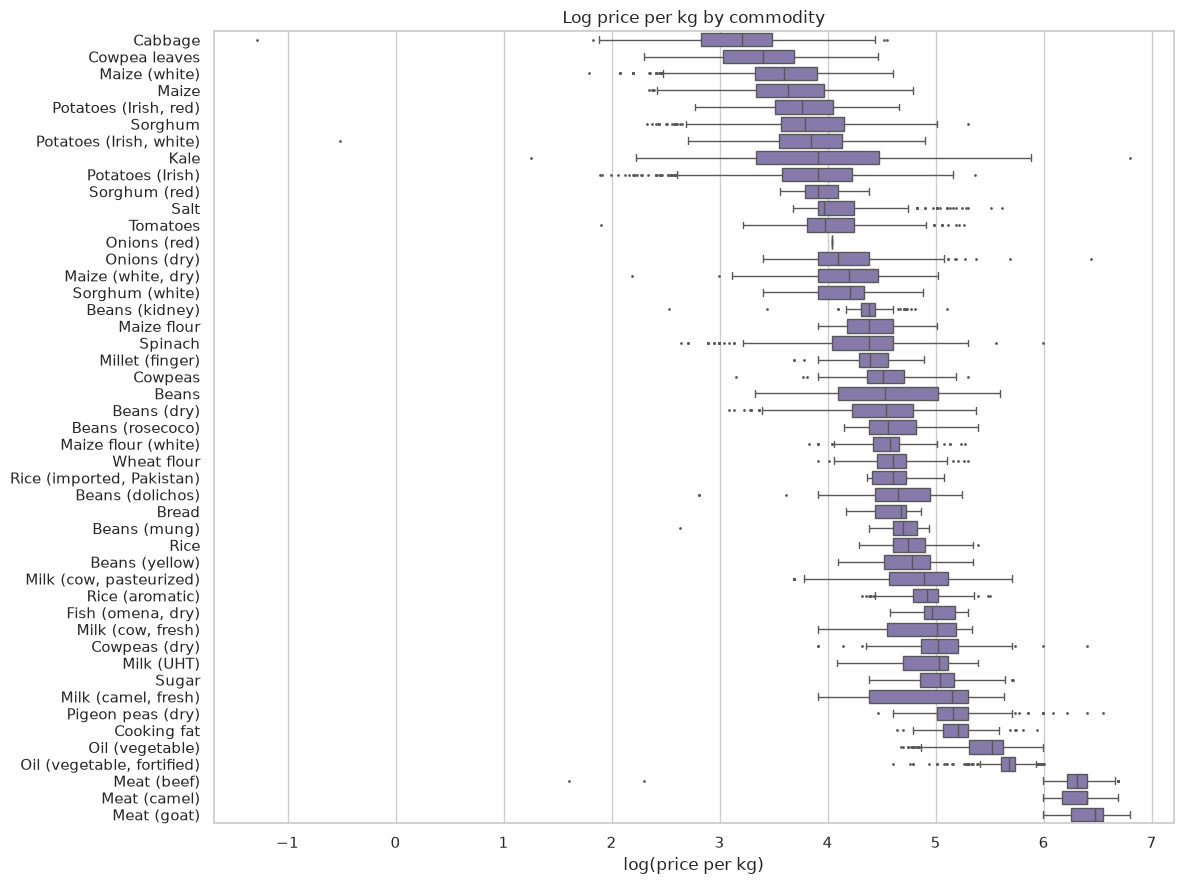

In [9]:
order = data.groupby("commodity")[TARGET].median().sort_values().index
plt.figure(figsize=(12, 9))
sns.boxplot(data=data, y="commodity", x=np.log(data[TARGET]), order=order, color="#8172B2", fliersize=1)
plt.xlabel("log(price per kg)"); plt.ylabel(""); plt.title("Log price per kg by commodity")
plt.tight_layout(); plt.show()

**What it shows:** the commodity explains most of the price — the medians range from cheap staples (maize, sorghum) to
expensive goods (meat, milk powder, cooking oil) across several log units, while the spread within one commodity is small.

**Decision:** `commodity` must be one-hot encoded and kept; it is the most important feature. Because the effect of a
commodity also depends on region and channel (interactions), I expect tree ensembles to beat linear models.

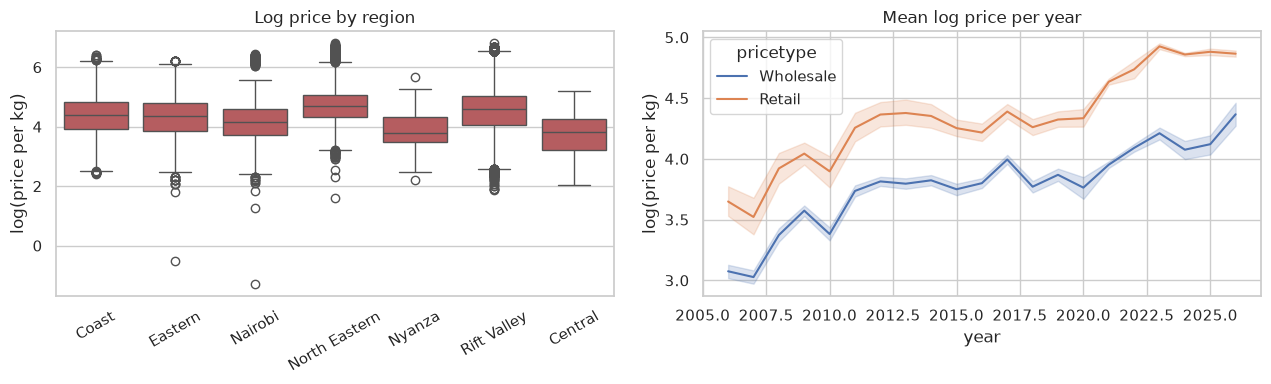

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=data, x="admin1", y=np.log(data[TARGET]), ax=axes[0], color="#C44E52")
axes[0].set(title="Log price by region", xlabel="", ylabel="log(price per kg)"); axes[0].tick_params(axis="x", rotation=30)
sns.lineplot(data=data.assign(lp=np.log(data[TARGET])), x="year", y="lp", hue="pricetype", ax=axes[1])
axes[1].set(title="Mean log price per year", ylabel="log(price per kg)")
plt.tight_layout(); plt.show()

**What it shows:** North Eastern (arid, far from production areas) is the most expensive region, and prices rise steadily over
time with a jump after 2021; retail is always above wholesale.

**Decision:** keep `admin1`, `year` and `pricetype` as features. Region and price type are one-hot encoded.

## 4. Encode, split and standardise

- Categorical columns → numeric with **one-hot encoding**.
- 80/20 train/test split (`random_state=42`); all four models are evaluated on this same test set.
- **StandardScaler** is fitted on the training set only, then applied to the test set.
- For tuning SGD I carve a validation set out of the training data, so the test set is never used to choose hyperparameters.

In [11]:
X = data[FEATURES]
y = np.log(data[TARGET])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)


def make_preprocessor():
    encode = ColumnTransformer(
        [("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)],
        remainder="passthrough",
    )
    return Pipeline([("encode", encode), ("scale", StandardScaler())])


preprocessor = make_preprocessor().fit(X_train)       # fitted on TRAIN only
X_train_s = preprocessor.transform(X_train)
X_test_s = preprocessor.transform(X_test)
print("Train:", X_train_s.shape, " Test:", X_test_s.shape)
print("Train feature means ~0:", X_train_s.mean().round(4), " stds ~1:", X_train_s.std().round(4))

Train: (22698, 60)  Test: (5675, 60)
Train feature means ~0: 0.0  stds ~1: 1.0


## 5. Model 1 — Linear regression by gradient descent (`SGDRegressor`)

scikit-learn does not record per-epoch loss, so I train with `partial_fit` in a loop (one pass over shuffled data per epoch)
and record train and validation/test MSE after every epoch.

### 5.1 Hyperparameter tuning
Grid: learning rate `eta0` ∈ {0.0005, 0.005, 0.05}, L2 regularisation `alpha` ∈ {1e-5, 1e-3, 1e-1}, epochs up to 100
(the best epoch count is read off the validation curve).

In [12]:
X_tr_s, X_val_s, y_tr, y_val = train_test_split(X_train_s, y_train.values, test_size=0.2, random_state=RANDOM_STATE)


def train_sgd(X_a, y_a, X_b, y_b, eta0, alpha, epochs, seed=RANDOM_STATE):
    """Train SGDRegressor epoch by epoch; return model and per-epoch MSE on (a) and (b)."""
    sgd = SGDRegressor(eta0=eta0, alpha=alpha, penalty="l2", learning_rate="invscaling", random_state=seed)
    rng = np.random.default_rng(seed)
    loss_a, loss_b = [], []
    for _ in range(epochs):
        idx = rng.permutation(len(X_a))
        sgd.partial_fit(X_a[idx], y_a[idx])
        loss_a.append(mean_squared_error(y_a, sgd.predict(X_a)))
        loss_b.append(mean_squared_error(y_b, sgd.predict(X_b)))
    return sgd, loss_a, loss_b


results = []
for eta0 in [0.0005, 0.005, 0.05]:
    for alpha in [1e-5, 1e-3, 1e-1]:
        _, tr, val = train_sgd(X_tr_s, y_tr, X_val_s, y_val, eta0, alpha, epochs=100)
        best_ep = int(np.argmin(val)) + 1
        results.append({"eta0": eta0, "alpha": alpha, "epochs_run": 100,
                        "best_epoch": best_ep, "best_val_mse": min(val), "val_mse_at_10": val[9], "final_val_mse": val[-1]})

tuning = pd.DataFrame(results).sort_values("best_val_mse")
tuning

,eta0,alpha,epochs_run,best_epoch,best_val_mse,val_mse_at_10,final_val_mse
3,0.0050,0.00001,100,85,7.553934e-02,7.595422e-02,7.574310e-02
4,0.0050,0.00100,100,85,7.555394e-02,7.596949e-02,7.576157e-02
0,0.0005,0.00001,100,100,7.581447e-02,7.723563e-02,7.581447e-02
1,0.0005,0.00100,100,100,7.582883e-02,7.725046e-02,7.582883e-02
5,0.0050,0.10000,100,66,7.960674e-02,8.030614e-02,8.038700e-02
2,0.0005,0.10000,100,66,8.000450e-02,8.102973e-02,8.004176e-02
8,0.0500,0.10000,100,100,3.075299e+03,1.054627e+21,3.075299e+03
7,0.0500,0.00100,100,98,2.213881e+20,3.922131e+21,2.244032e+20
6,0.0500,0.00001,100,100,2.503523e+20,2.222564e+21,2.503523e+20


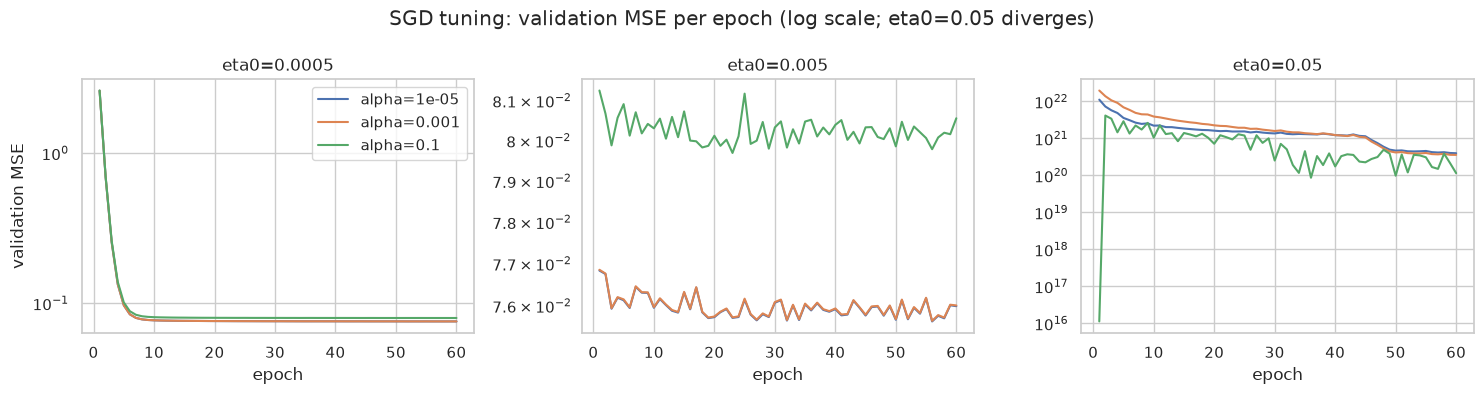

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, eta0 in zip(axes, [0.0005, 0.005, 0.05]):
    for alpha in [1e-5, 1e-3, 1e-1]:
        _, _, val = train_sgd(X_tr_s, y_tr, X_val_s, y_val, eta0, alpha, epochs=60)
        ax.plot(range(1, 61), val, label=f"alpha={alpha}")
    ax.set(title=f"eta0={eta0}", xlabel="epoch", yscale="log")
axes[0].set_ylabel("validation MSE"); axes[0].legend()
plt.suptitle("SGD tuning: validation MSE per epoch (log scale; eta0=0.05 diverges)"); plt.tight_layout(); plt.show()

In [14]:
best_cfg = tuning.iloc[0]
BEST_ETA0, BEST_ALPHA = float(best_cfg["eta0"]), float(best_cfg["alpha"])
BEST_EPOCHS = max(int(best_cfg["best_epoch"]), 10)
print(f"Chosen SGD config: eta0={BEST_ETA0}, alpha={BEST_ALPHA}, epochs={BEST_EPOCHS}")

Chosen SGD config: eta0=0.005, alpha=1e-05, epochs=85


**Effect of each hyperparameter**
- **Learning rate (`eta0`)**: 0.0005 converges slowly (loss still falling at epoch 100); 0.005 reaches the lowest validation
  MSE; 0.05 is too large — the updates overshoot and the loss **diverges** to astronomically large values (see the table).
- **Regularisation (`alpha`)**: 1e-5 and 1e-3 give almost identical loss (the model has few features compared with 22k rows,
  so it is not overfitting); `alpha=0.1` shrinks the weights too much and clearly *raises* the loss (underfitting).
- **Epochs**: with eta0=0.005 most of the gain happens in the first ~10 epochs, after which the validation loss creeps down
  only slightly; I stop at the epoch where it bottoms out.

### 5.2 Loss curve — train vs test MSE per epoch (final SGD model)

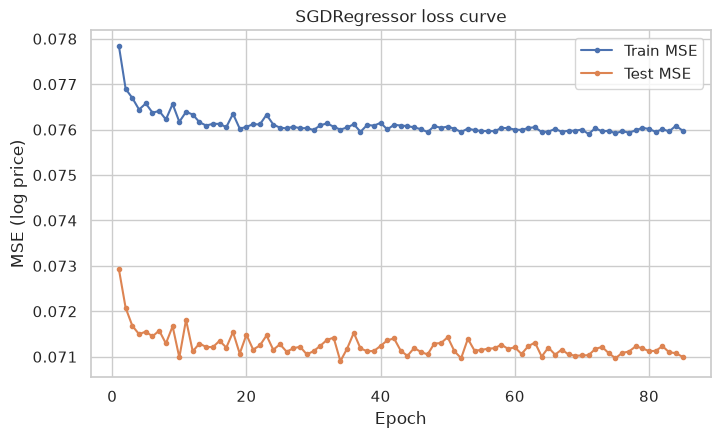

Final train MSE: 0.07597838921195106  test MSE: 0.07099886354145243


In [15]:
sgd, sgd_train_curve, sgd_test_curve = train_sgd(X_train_s, y_train.values, X_test_s, y_test.values,
                                                 BEST_ETA0, BEST_ALPHA, epochs=BEST_EPOCHS)
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, BEST_EPOCHS + 1), sgd_train_curve, marker="o", ms=3, label="Train MSE")
plt.plot(range(1, BEST_EPOCHS + 1), sgd_test_curve, marker="o", ms=3, label="Test MSE")
plt.xlabel("Epoch"); plt.ylabel("MSE (log price)"); plt.title("SGDRegressor loss curve")
plt.legend(); plt.show()
print("Final train MSE:", sgd_train_curve[-1], " test MSE:", sgd_test_curve[-1])

Train and test curves fall together and stay close (test is slightly *below* train simply because this random test split
happens to contain a few fewer hard-to-price rows), so the linear model is **not overfitting** — its error is bias: a single
linear equation cannot capture interactions such as "milk is expensive *in the north*".

## 6. Models 2–4 — Linear regression (closed form), decision tree, random forest

In [16]:
lin = LinearRegression().fit(X_train_s, y_train)

# light depth tuning for the tree on the validation split
tree_val = {}
for depth in [5, 10, 15, 20, None]:
    t = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=3, random_state=RANDOM_STATE).fit(X_tr_s, y_tr)
    tree_val[depth] = mean_squared_error(y_val, t.predict(X_val_s))
    print(f"tree max_depth={depth}: val MSE={tree_val[depth]:.4f}")
BEST_DEPTH = min(tree_val, key=tree_val.get)
print("Chosen max_depth:", BEST_DEPTH)

tree max_depth=5: val MSE=0.2321
tree max_depth=10: val MSE=0.0935
tree max_depth=15: val MSE=0.0550


tree max_depth=20: val MSE=0.0417


tree max_depth=None: val MSE=0.0392
Chosen max_depth: None


In [17]:
tree = DecisionTreeRegressor(max_depth=BEST_DEPTH, min_samples_leaf=3, random_state=RANDOM_STATE).fit(X_train_s, y_train)
forest = RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=2,
                               n_jobs=-1, random_state=RANDOM_STATE).fit(X_train_s, y_train)

## 7. Comparison of all four models (same test set)

In [18]:
models = {
    "Linear regression (gradient descent, SGDRegressor)": sgd,
    "Linear regression (closed form, LinearRegression)": lin,
    "Decision tree (DecisionTreeRegressor)": tree,
    "Random forest (RandomForestRegressor)": forest,
}
rows = []
for name, m in models.items():
    p_test = m.predict(X_test_s)
    rows.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, m.predict(X_train_s)),
        "Test MSE": mean_squared_error(y_test, p_test),
        "Test RMSE (KES/kg)": np.sqrt(mean_squared_error(np.exp(y_test), np.exp(p_test))),
    })
comparison = pd.DataFrame(rows).sort_values("Test MSE").reset_index(drop=True)
comparison.style.format({"Train MSE": "{:.4f}", "Test MSE": "{:.4f}", "Test RMSE (KES/kg)": "{:.1f}"})

,Model,Train MSE,Test MSE,Test RMSE (KES/kg)
0,Random forest (RandomForestRegressor),0.0208,0.0309,20.9
1,Decision tree (DecisionTreeRegressor),0.0133,0.0357,22.1
2,"Linear regression (closed form, LinearRegression)",0.0758,0.0710,28.9
3,"Linear regression (gradient descent, SGDRegressor)",0.0760,0.0710,28.8


In [19]:
best_name = comparison.loc[0, "Model"]
print(f"BEST MODEL (lowest test MSE): {best_name}  ->  test MSE = {comparison.loc[0, 'Test MSE']:.4f}")

BEST MODEL (lowest test MSE): Random forest (RandomForestRegressor)  ->  test MSE = 0.0309


**Best model: Random forest** — it has the lowest test MSE (MSE is on log price per kg; RMSE in KES/kg is shown for
interpretation).

**How the dataset affected each model**
- **The two linear models** (SGD and closed form) land at almost the same MSE — gradient descent converged to the same solution
  as the exact formula. Both are limited because price depends on *combinations* of commodity, region, channel and year, which a
  single additive equation cannot express.
- **Decision tree** captures those interactions and cuts the error substantially, but a single deep tree has a train/test gap
  (some overfitting to particular markets and months).
- **Random forest** averages 100 trees trained on bootstrap samples, keeping the tree's ability to model interactions while
  reducing its variance, so it has the lowest test error. With ~28k rows and mostly categorical structure, this is the
  expected winner, and it fits the problem: farmers need an accurate price for a specific crop, market and month.

### Which features matter most

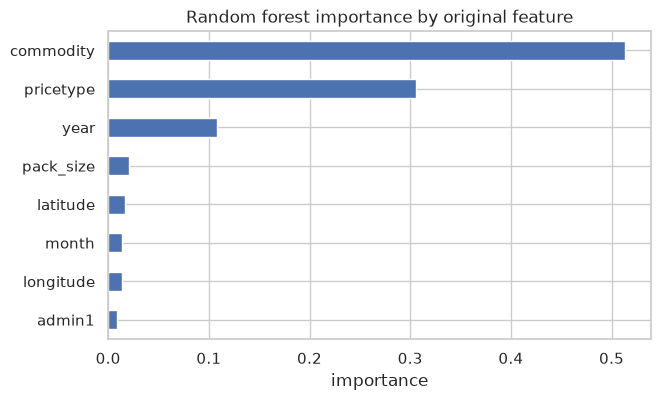

commodity    0.513177
pricetype    0.306035
year         0.108132
pack_size    0.020276
latitude     0.016633
month        0.013496
longitude    0.013223
admin1       0.009029
dtype: float64

In [20]:
names = preprocessor.named_steps["encode"].get_feature_names_out()
imp = pd.Series(forest.feature_importances_, index=names)
def original_feature(name):
    prefix, rest = name.split("__", 1)
    if prefix == "onehot":
        return next(c for c in CATEGORICAL if rest.startswith(c + "_"))
    return rest

grouped = imp.groupby(original_feature).sum()
grouped = grouped.sort_values(ascending=True)
grouped.plot.barh(figsize=(7, 4), color="#4C72B0", title="Random forest importance by original feature")
plt.xlabel("importance"); plt.show()
grouped.sort_values(ascending=False)

`commodity` dominates (~half of the importance), followed by `pricetype` (retail vs wholesale) and `year` (inflation).
`pack_size` scores low only because it carries almost the same information as `pricetype`; location and month add smaller
refinements.

## 8. Scatter plots — most correlated feature vs target

From the heatmap, the continuous feature most correlated with log price is `year` (r ≈ 0.52) — `is_wholesale` is a 0/1 flag,
which would not make a meaningful scatter. Points are jittered slightly so they don't stack on whole years.

Most correlated feature: year (r = 0.52)


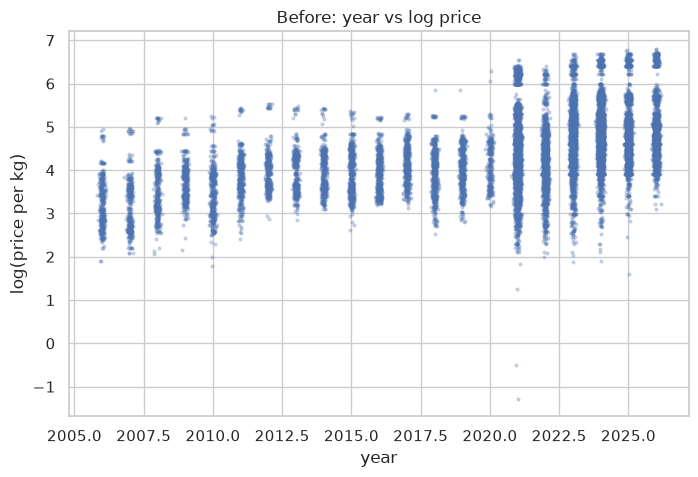

In [21]:
corr = corr_df.corr()["log_price_per_kg"][NUMERIC]   # continuous columns only (is_wholesale is a 0/1 flag)
top_feature = corr.abs().idxmax()
print("Most correlated feature:", top_feature, f"(r = {corr[top_feature]:.2f})")

x_plot = np.log(data[top_feature]) if top_feature == "pack_size" else data[top_feature]
x_label = "log(pack size in kg)" if top_feature == "pack_size" else top_feature
y_plot = np.log(data[TARGET])
jitter = np.random.default_rng(0).normal(0, 0.05, len(x_plot))

plt.figure(figsize=(8, 5))
plt.scatter(x_plot + jitter, y_plot, s=4, alpha=0.25)
plt.xlabel(x_label); plt.ylabel("log(price per kg)"); plt.title(f"Before: {x_label} vs log price")
plt.show()

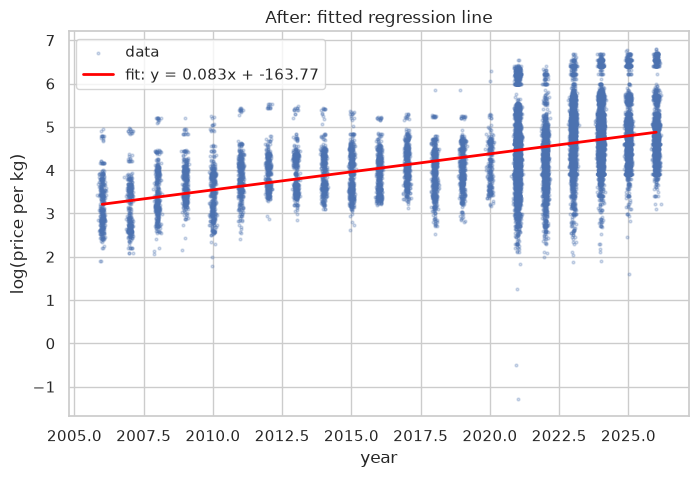

In [22]:
one_feat = LinearRegression().fit(x_plot.values.reshape(-1, 1), y_plot)   # one-feature fit, for this plot only
xs = np.linspace(x_plot.min(), x_plot.max(), 100)

plt.figure(figsize=(8, 5))
plt.scatter(x_plot + jitter, y_plot, s=4, alpha=0.25, label="data")
plt.plot(xs, one_feat.predict(xs.reshape(-1, 1)), color="red", lw=2,
         label=f"fit: y = {one_feat.coef_[0]:.3f}x + {one_feat.intercept_:.2f}")
plt.xlabel(x_label); plt.ylabel("log(price per kg)"); plt.title(f"After: fitted regression line")
plt.legend(); plt.show()

## 9. Save the best model with its preprocessing

The saved object is a single scikit-learn estimator: a `Pipeline` (one-hot encode → standardise → random forest) wrapped in a
`TransformedTargetRegressor` that applies `log` to the target during fitting and `exp` when predicting. So the API sends raw
inputs (e.g. `"Maize (white)"`, `"Wholesale"`, `90`) and gets back KES per kg directly.

In [23]:
best_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=2,
                                        n_jobs=-1, random_state=RANDOM_STATE)),
    ]),
    func=np.log, inverse_func=np.exp, check_inverse=False,
)
best_model.fit(X_train, np.exp(y_train))        # raw KES/kg target, log applied inside

check = mean_squared_error(y_test, np.log(best_model.predict(X_test)))
print(f"Saved pipeline test MSE (log scale): {check:.4f}")

joblib.dump(best_model, "../API/best_model.pkl", compress=3)
print("Saved to ../API/best_model.pkl")

Saved pipeline test MSE (log scale): 0.0309


Saved to ../API/best_model.pkl


## 10. Load the saved model and predict one test row (reused by the API)

In [24]:
def predict_price(row: dict, model_path: str = "../API/best_model.pkl") -> float:
    """Load the saved pipeline and return the predicted price in KES per kg for one input row."""
    model = joblib.load(model_path)
    X_row = pd.DataFrame([row], columns=FEATURES)
    return float(model.predict(X_row)[0])


sample = X_test.iloc[0].to_dict()
print("Input:", sample)
print(f"Predicted: {predict_price(sample):.2f} KES/kg   |   Actual: {np.exp(y_test.iloc[0]):.2f} KES/kg")

Input: {'commodity': 'Meat (beef)', 'pricetype': 'Retail', 'admin1': 'Eastern', 'latitude': 0.35, 'longitude': 37.58, 'year': 2021, 'month': 11, 'pack_size': 1.0}


Predicted: 547.48 KES/kg   |   Actual: 500.00 KES/kg


In [25]:
# Valid values the API will accept for the categorical inputs
print("pricetype:", sorted(data["pricetype"].unique()))
print("admin1:", sorted(data["admin1"].unique()))
print("commodity:", sorted(data["commodity"].unique()))

pricetype: ['Retail', 'Wholesale']
admin1: ['Central', 'Coast', 'Eastern', 'Nairobi', 'North Eastern', 'Nyanza', 'Rift Valley']
commodity: ['Beans', 'Beans (dolichos)', 'Beans (dry)', 'Beans (kidney)', 'Beans (mung)', 'Beans (rosecoco)', 'Beans (yellow)', 'Bread', 'Cabbage', 'Cooking fat', 'Cowpea leaves', 'Cowpeas', 'Cowpeas (dry)', 'Fish (omena, dry)', 'Kale', 'Maize', 'Maize (white)', 'Maize (white, dry)', 'Maize flour', 'Maize flour (white)', 'Meat (beef)', 'Meat (camel)', 'Meat (goat)', 'Milk (UHT)', 'Milk (camel, fresh)', 'Milk (cow, fresh)', 'Milk (cow, pasteurized)', 'Millet (finger)', 'Oil (vegetable)', 'Oil (vegetable, fortified)', 'Onions (dry)', 'Onions (red)', 'Pigeon peas (dry)', 'Potatoes (Irish)', 'Potatoes (Irish, red)', 'Potatoes (Irish, white)', 'Rice', 'Rice (aromatic)', 'Rice (imported, Pakistan)', 'Salt', 'Sorghum', 'Sorghum (red)', 'Sorghum (white)', 'Spinach', 'Sugar', 'Tomatoes', 'Wheat flour']
